# FinTech Fraud Detection — Exploratory Data Analysis

This notebook turns the hackathon EDA into a reproducible, presentation-ready workflow. It focuses on patterns that improve **top-1% investigation prioritization**, not generic classification accuracy.

**Before running:** the notebook expects `pandas`, `numpy`, `matplotlib`, and `seaborn`. If needed, uncomment and run `%pip install pandas numpy matplotlib seaborn`. Update `DATA_PATH` if your CSV lives elsewhere.


In [2]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
# %pip install pandas numpy matplotlib seaborn

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DATA_PATH = Path('/Users/yilingz/Downloads/train_data.csv')
assert DATA_PATH.exists(), f'Update DATA_PATH: {DATA_PATH} was not found.'

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'legitimate': '#4C78A8', 'fraud': '#E45756', 'accent': '#72B7B2'}
RANDOM_STATE = 42


## 1. Load data and dataset health

The fraud label is highly imbalanced, so the table records data completeness and class balance before any visual analysis.


In [4]:
df = pd.read_csv(DATA_PATH)

required_columns = {
    'time_step', 'transaction_type', 'transaction_amount', 'sender_id',
    'sender_balance_before', 'sender_balance_after', 'recipient_id',
    'recipient_balance_before', 'recipient_balance_after', 'is_fraud',
    'is_flagged_fraud'
}
missing_required = required_columns - set(df.columns)
assert not missing_required, f'Missing expected columns: {missing_required}'

health = pd.DataFrame({
    'Metric': [
        'Rows', 'Columns', 'Fraud cases', 'Fraud rate', 'Missing values',
        'Exact duplicate rows', 'Time-step range', 'Unique senders',
        'Unique recipients', 'Flagged-fraud cases'
    ],
    'Value': [
        f'{len(df):,}', len(df.columns), f"{df['is_fraud'].sum():,}",
        f"{df['is_fraud'].mean():.3%}", int(df.isna().sum().sum()),
        f'{df.duplicated().sum():,}',
        f"{df['time_step'].min()}–{df['time_step'].max()}",
        f"{df['sender_id'].nunique():,}", f"{df['recipient_id'].nunique():,}",
        f"{df['is_flagged_fraud'].sum():,}"
    ],
})

display(health)
display(df.head())


,Metric,Value
0,Rows,"509,009"
1,Columns,11
2,Fraud cases,654
3,Fraud rate,0.128%
4,Missing values,0
5,Exact duplicate rows,0
6,Time-step range,1–742
7,Unique senders,"508,956"
8,Unique recipients,"383,327"
9,Flagged-fraud cases,0


,time_step,transaction_type,transaction_amount,sender_id,sender_balance_before,sender_balance_after,recipient_id,recipient_balance_before,recipient_balance_after,is_fraud,is_flagged_fraud
0,301,TRANSFER,2613884.90,C1064844674,51032.0,0.0,C1076862073,1149255.09,3763139.99,0,0
1,181,PAYMENT,22187.07,C901544552,640.0,0.0,M1810254537,0.00,0.00,0,0
2,17,TRANSFER,83313.04,C1730987356,0.0,0.0,C891299120,343593.00,854642.04,0,0
3,239,CASH_OUT,555435.39,C826783665,0.0,0.0,C1736189812,3893218.73,4448654.13,0,0
4,378,CASH_OUT,71061.03,C288221910,13628.0,0.0,C1732276736,100338.56,171399.58,0,0


## 2. Where fraud is happening: transaction type

The left panel is a compact table; the two charts separate total volume from fraud-case counts so the much smaller fraud counts remain visible.


,transaction_type,transactions,fraud_cases,fraud_rate
0,TRANSFER,42796,331,0.773%
1,CASH_OUT,179080,323,0.180%
2,CASH_IN,111635,0,0.000%
3,DEBIT,3295,0,0.000%
4,PAYMENT,172203,0,0.000%


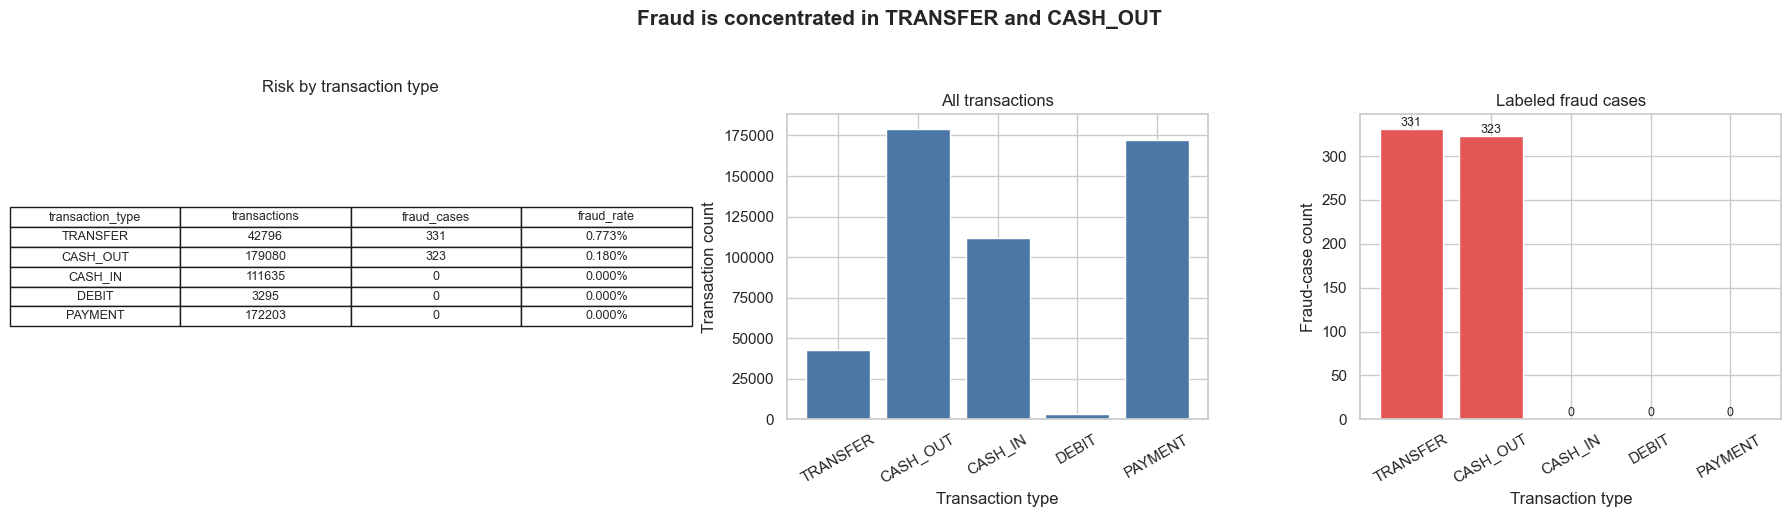

In [5]:
type_summary = (
    df.groupby('transaction_type', observed=False)['is_fraud']
      .agg(transactions='size', fraud_cases='sum', fraud_rate='mean')
      .sort_values('fraud_rate', ascending=False)
      .reset_index()
)
type_summary['fraud_rate'] = type_summary['fraud_rate'].map('{:.3%}'.format)

display(type_summary)

plot_types = type_summary.copy()
plot_types['fraud_rate'] = plot_types['fraud_rate'].str.rstrip('%').astype(float) / 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.35, 1, 1]})
axes[0].axis('off')
table = axes[0].table(
    cellText=type_summary.values, colLabels=type_summary.columns,
    cellLoc='center', loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)
axes[0].set_title('Risk by transaction type', pad=16)

axes[1].bar(plot_types['transaction_type'], plot_types['transactions'], color=PALETTE['legitimate'])
axes[1].set_title('All transactions')
axes[1].set_xlabel('Transaction type')
axes[1].set_ylabel('Transaction count')
axes[1].tick_params(axis='x', rotation=30)

axes[2].bar(plot_types['transaction_type'], plot_types['fraud_cases'], color=PALETTE['fraud'])
axes[2].set_title('Labeled fraud cases')
axes[2].set_xlabel('Transaction type')
axes[2].set_ylabel('Fraud-case count')
axes[2].tick_params(axis='x', rotation=30)
for i, value in enumerate(plot_types['fraud_cases']):
    axes[2].text(i, value, f'{value:,}', ha='center', va='bottom', fontsize=9)

fig.suptitle('Fraud is concentrated in TRANSFER and CASH_OUT', y=1.03, fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()


## 3. High-signal behavior patterns

These are descriptive balance behaviors. The bar height is fraud rate; labels show the fraud cases captured and the total number of transactions in each segment.


,Behavior,Transactions,Fraud cases,Fraud rate,Fraud recall
0,Sender balance emptied,121976,645,0.529%,98.6%
1,Recipient starts at $0,216179,441,0.204%,67.4%
2,Sender balance change = amount,103683,654,0.631%,100.0%
3,TRANSFER + emptied sender + new recipient,4863,323,6.642%,49.4%


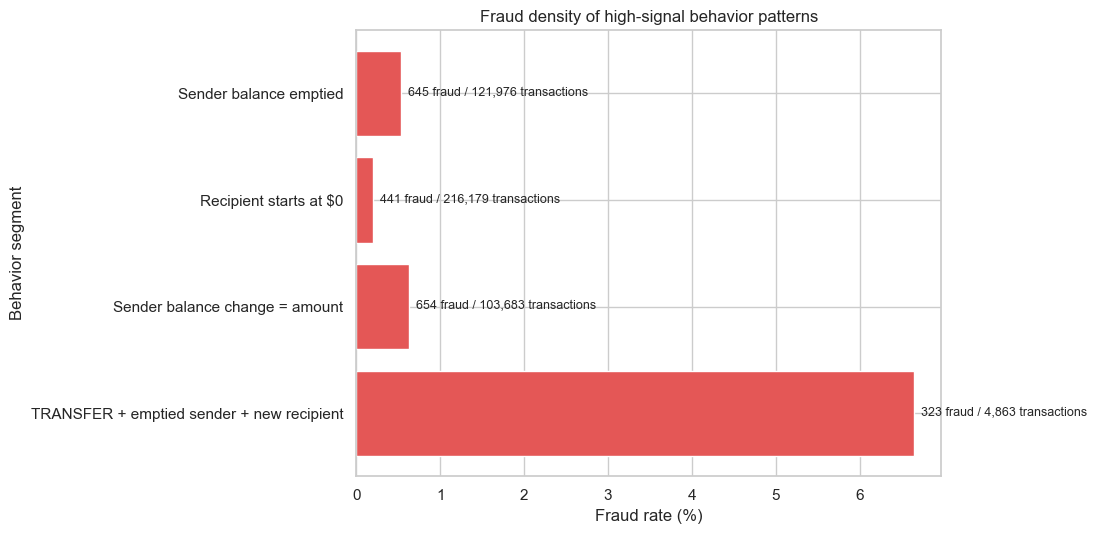

In [6]:
# Derived behaviors used only for EDA. Confirm that post-transaction balances are
# available at the future scoring decision point before using them in a live model.
df['sender_emptied'] = (
    (df['sender_balance_before'] > 0) & (df['sender_balance_after'] == 0)
)
df['recipient_new'] = df['recipient_balance_before'].eq(0)
df['exact_sender_amount'] = np.isclose(
    df['sender_balance_before'] - df['sender_balance_after'],
    df['transaction_amount'],
    atol=0.01, rtol=0
)
df['transfer_empty_new'] = (
    df['transaction_type'].eq('TRANSFER')
    & df['sender_emptied']
    & df['recipient_new']
)

behavior_definitions = {
    'Sender balance emptied': 'sender_emptied',
    'Recipient starts at $0': 'recipient_new',
    'Sender balance change = amount': 'exact_sender_amount',
    'TRANSFER + emptied sender + new recipient': 'transfer_empty_new',
}

behavior_summary = pd.DataFrame([
    {
        'Behavior': label,
        'Transactions': int(df[column].sum()),
        'Fraud cases': int(df.loc[df[column], 'is_fraud'].sum()),
        'Fraud rate': df.loc[df[column], 'is_fraud'].mean(),
        'Fraud recall': df.loc[df[column], 'is_fraud'].sum() / df['is_fraud'].sum(),
    }
    for label, column in behavior_definitions.items()
])

display(behavior_summary.style.format({'Fraud rate': '{:.3%}', 'Fraud recall': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(behavior_summary['Behavior'], behavior_summary['Fraud rate'] * 100, color=PALETTE['fraud'])
ax.set_xlabel('Fraud rate (%)')
ax.set_ylabel('Behavior segment')
ax.set_title('Fraud density of high-signal behavior patterns')
for bar, (_, row) in zip(bars, behavior_summary.iterrows()):
    ax.text(
        bar.get_width(), bar.get_y() + bar.get_height()/2,
        f"  {row['Fraud cases']:,} fraud / {row['Transactions']:,} transactions",
        va='center', fontsize=9
    )
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 4. Distribution of transaction amounts

A log x-axis makes the long right tail visible while preserving the comparison between fraud and legitimate transaction amounts.


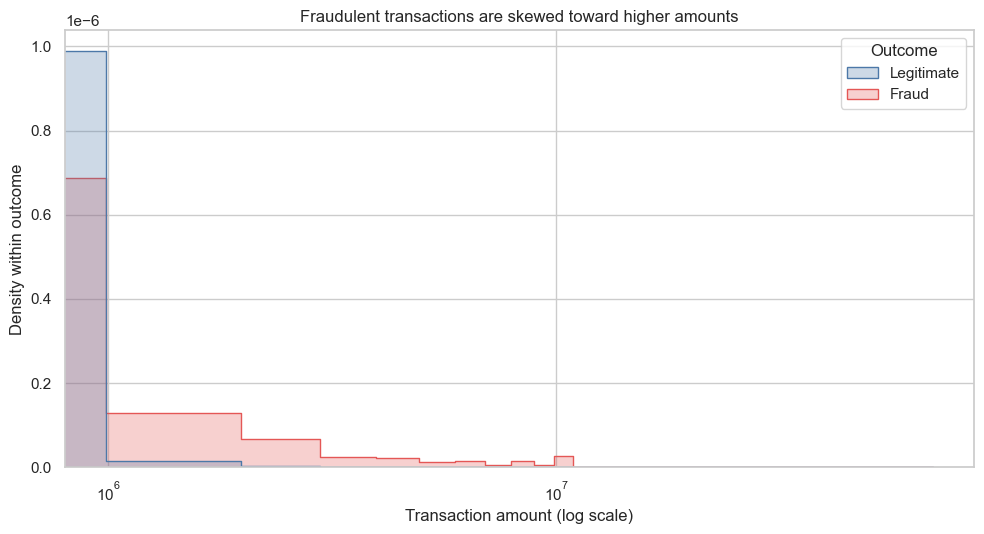

,count,median,mean,p95
is_fraud,,,,
Legitimate,508355,"$74,796","$179,827","$518,402"
Fraud,654,"$447,300","$1,334,151","$6,943,095"


In [7]:
plot_df = df[['transaction_amount', 'is_fraud']].copy()
plot_df['Outcome'] = plot_df['is_fraud'].map({0: 'Legitimate', 1: 'Fraud'})

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(
    data=plot_df, x='transaction_amount', hue='Outcome',
    bins=70, stat='density', common_norm=False, element='step',
    fill=True, alpha=0.28, palette={'Legitimate': PALETTE['legitimate'], 'Fraud': PALETTE['fraud']},
    ax=ax
)
ax.set_xscale('log')
ax.set_xlabel('Transaction amount (log scale)')
ax.set_ylabel('Density within outcome')
ax.set_title('Fraudulent transactions are skewed toward higher amounts')
plt.tight_layout()
plt.show()

amount_summary = (
    df.groupby('is_fraud')['transaction_amount']
      .agg(['count', 'median', 'mean', lambda s: s.quantile(.95)])
      .rename(index={0: 'Legitimate', 1: 'Fraud'}, columns={'<lambda_0>': 'p95'})
)
display(amount_summary.style.format({'median': '${:,.0f}', 'mean': '${:,.0f}', 'p95': '${:,.0f}'}))


## 5. Temporal patterns: hour-of-day EDA

`time_step` represents elapsed hours. Taking modulo 24 creates an hour-of-day feature; this chart shows the number of labeled fraud transactions in each 24-hour position.


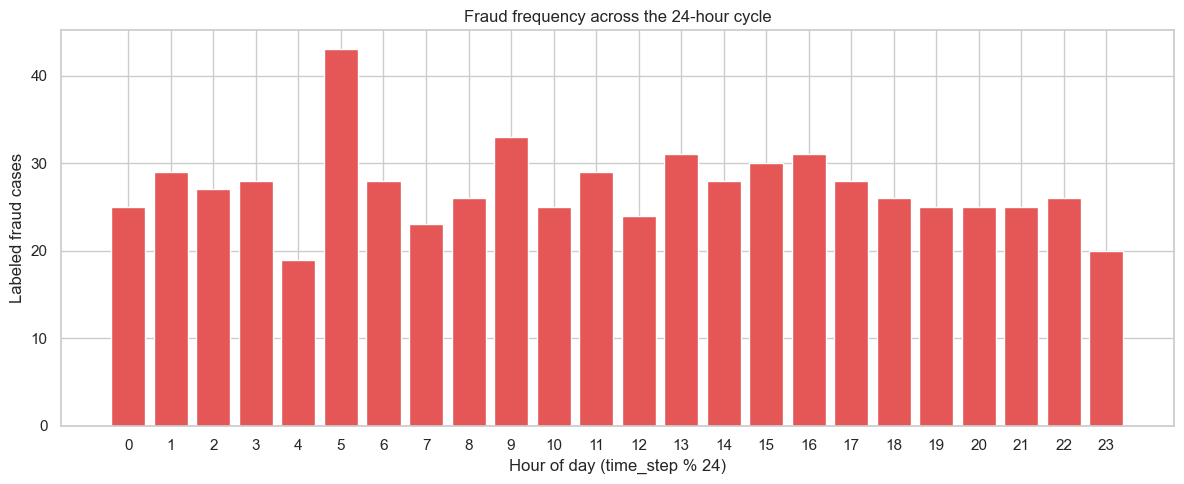

,hour_of_day,fraud_cases,transactions,fraud_rate
0,0,25,5630,0.444%
1,1,29,2169,1.337%
2,2,27,678,3.982%
3,3,28,152,18.421%
4,4,19,106,17.925%
5,5,43,151,28.477%
6,6,28,275,10.182%
7,7,23,694,3.314%
8,8,26,2215,1.174%
9,9,33,22418,0.147%


In [8]:
df['hour_of_day'] = df['time_step'] % 24
hourly_fraud = (
    df.groupby('hour_of_day', as_index=False)['is_fraud']
      .agg(fraud_cases='sum', transactions='size')
)
hourly_fraud['fraud_rate'] = hourly_fraud['fraud_cases'] / hourly_fraud['transactions']

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hourly_fraud['hour_of_day'], hourly_fraud['fraud_cases'], color=PALETTE['fraud'], width=.8)
ax.set_xticks(range(24))
ax.set_xlabel('Hour of day (time_step % 24)')
ax.set_ylabel('Labeled fraud cases')
ax.set_title('Fraud frequency across the 24-hour cycle')
plt.tight_layout()
plt.show()

display(hourly_fraud.style.format({'fraud_rate': '{:.3%}'}))


## 6. Account-flow validation: the balance math check

For an internally consistent sender ledger, `(sender_balance_before - transaction_amount) - sender_balance_after` equals zero. This scatter plot uses a reproducible 50,000-row sample for readability and highlights labeled fraud.


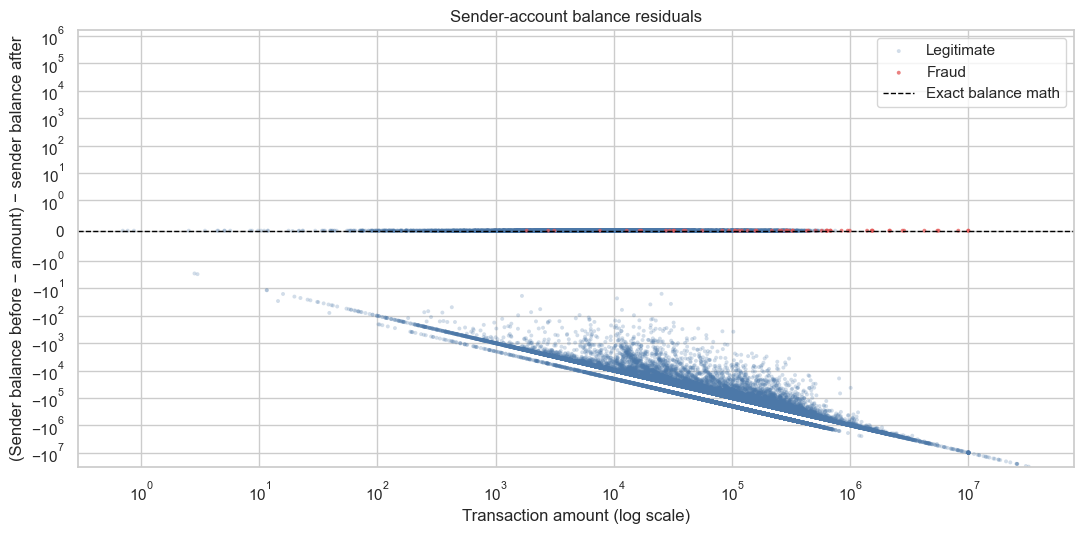

,Metric,Value
0,Exactly zero residual (all),14.92%
1,Exactly zero residual (fraud),99.08%
2,Median absolute residual,"$68,783.57"


In [12]:
df['sender_balance_residual'] = (
    df['sender_balance_before'] - df['transaction_amount'] - df['sender_balance_after']
)

scatter_df = df.sample(n=min(50_000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(11, 5.5))
for outcome, color, label in [(0, PALETTE['legitimate'], 'Legitimate'), (1, PALETTE['fraud'], 'Fraud')]:
    subset = scatter_df[scatter_df['is_fraud'].eq(outcome)]
    ax.scatter(
        subset['transaction_amount'], subset['sender_balance_residual'],
        s=8, alpha=.25 if outcome == 0 else .75, color=color, label=label, edgecolors='none'
    )
ax.axhline(0, color='black', linewidth=1, linestyle='--', label='Exact balance math')
ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('Transaction amount (log scale)')
ax.set_ylabel('(Sender balance before − amount) − sender balance after')
ax.set_title('Sender-account balance residuals')
ax.legend()
plt.tight_layout()
plt.show()

math_check = pd.DataFrame({
    'Metric': ['Exactly zero residual (all)', 'Exactly zero residual (fraud)', 'Median absolute residual'],
    'Value': [
        f"{df['sender_balance_residual'].eq(0).mean():.2%}",
        f"{df.loc[df['is_fraud'].eq(1), 'sender_balance_residual'].eq(0).mean():.2%}",
        f"${df['sender_balance_residual'].abs().median():,.2f}",
    ]
})
display(math_check)


## 7. Network frequency checks

Rather than encoding near-unique account IDs directly, first inspect whether repeatedly active accounts have a different fraud involvement rate. Points show accounts; the black diamonds summarize transaction-weighted fraud rate within frequency bands.


/var/folders/z6/g5jm1sp14pgfvww_gf0lyg980000gn/T/ipykernel_32795/450246056.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['fraud_transactions'].sum() / g['transaction_count'].sum())
/var/folders/z6/g5jm1sp14pgfvww_gf0lyg980000gn/T/ipykernel_32795/450246056.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['fraud_transactions'].sum() / g['transaction_count'].sum())


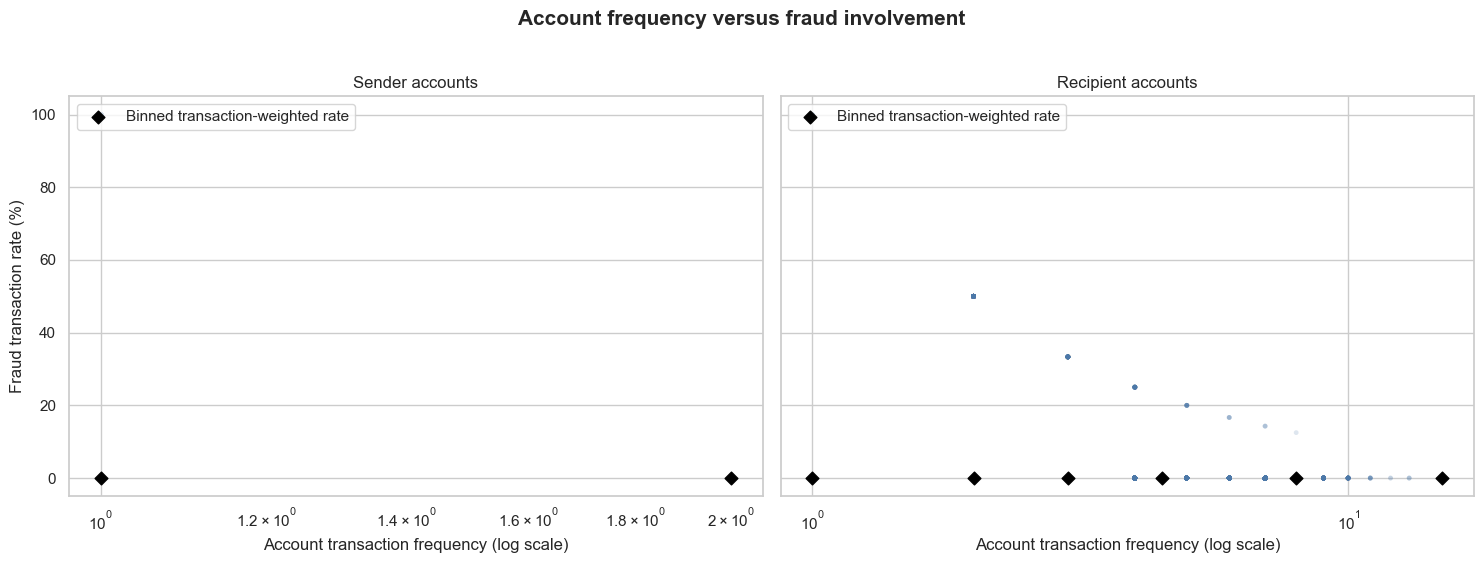

,Account role,Unique accounts,Accounts with ≥2 transactions,Accounts involved in ≥1 fraud
0,Sender,508956,53,654
1,Recipient,383327,76185,653


In [13]:
def account_frequency_summary(id_column):
    summary = (
        df.groupby(id_column)['is_fraud']
          .agg(transaction_count='size', fraud_transactions='sum')
          .reset_index()
    )
    summary['fraud_rate'] = summary['fraud_transactions'] / summary['transaction_count']
    summary['has_fraud'] = summary['fraud_transactions'].gt(0)
    return summary

def add_frequency_band(frame):
    bins = [0, 1, 2, 3, 5, 10, 20, 50, np.inf]
    labels = ['1', '2', '3', '4–5', '6–10', '11–20', '21–50', '51+']
    frame = frame.copy()
    frame['frequency_band'] = pd.cut(frame['transaction_count'], bins=bins, labels=labels)
    return frame

sender_accounts = add_frequency_band(account_frequency_summary('sender_id'))
recipient_accounts = add_frequency_band(account_frequency_summary('recipient_id'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, account_df, title in [
    (axes[0], sender_accounts, 'Sender accounts'),
    (axes[1], recipient_accounts, 'Recipient accounts'),
]:
    ax.scatter(
        account_df['transaction_count'], account_df['fraud_rate'] * 100,
        s=12, alpha=.18, color=PALETTE['legitimate'], edgecolors='none'
    )
    binned = (
        account_df.groupby('frequency_band', observed=True)
                  .apply(lambda g: g['fraud_transactions'].sum() / g['transaction_count'].sum())
                  .rename('fraud_rate')
                  .reset_index()
    )
    band_x = [1, 2, 3, 4.5, 8, 15, 35, 60]
    ax.scatter(band_x[:len(binned)], binned['fraud_rate'] * 100,
               color='black', marker='D', s=42, label='Binned transaction-weighted rate')
    ax.set_xscale('log')
    ax.set_xlabel('Account transaction frequency (log scale)')
    ax.set_title(title)
    ax.legend(loc='upper left')
axes[0].set_ylabel('Fraud transaction rate (%)')
fig.suptitle('Account frequency versus fraud involvement', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

frequency_overview = pd.DataFrame({
    'Account role': ['Sender', 'Recipient'],
    'Unique accounts': [sender_accounts.shape[0], recipient_accounts.shape[0]],
    'Accounts with ≥2 transactions': [
        sender_accounts['transaction_count'].ge(2).sum(),
        recipient_accounts['transaction_count'].ge(2).sum(),
    ],
    'Accounts involved in ≥1 fraud': [sender_accounts['has_fraud'].sum(), recipient_accounts['has_fraud'].sum()],
})
display(frequency_overview)


## 8. Correlations with encoded transaction type

Pearson correlation is shown for numeric fields plus one-hot transaction-type indicators. Raw account IDs are intentionally excluded: they are identifiers, not meaningful numeric quantities. The constant `is_flagged_fraud` field is also excluded because correlations with a constant are undefined.


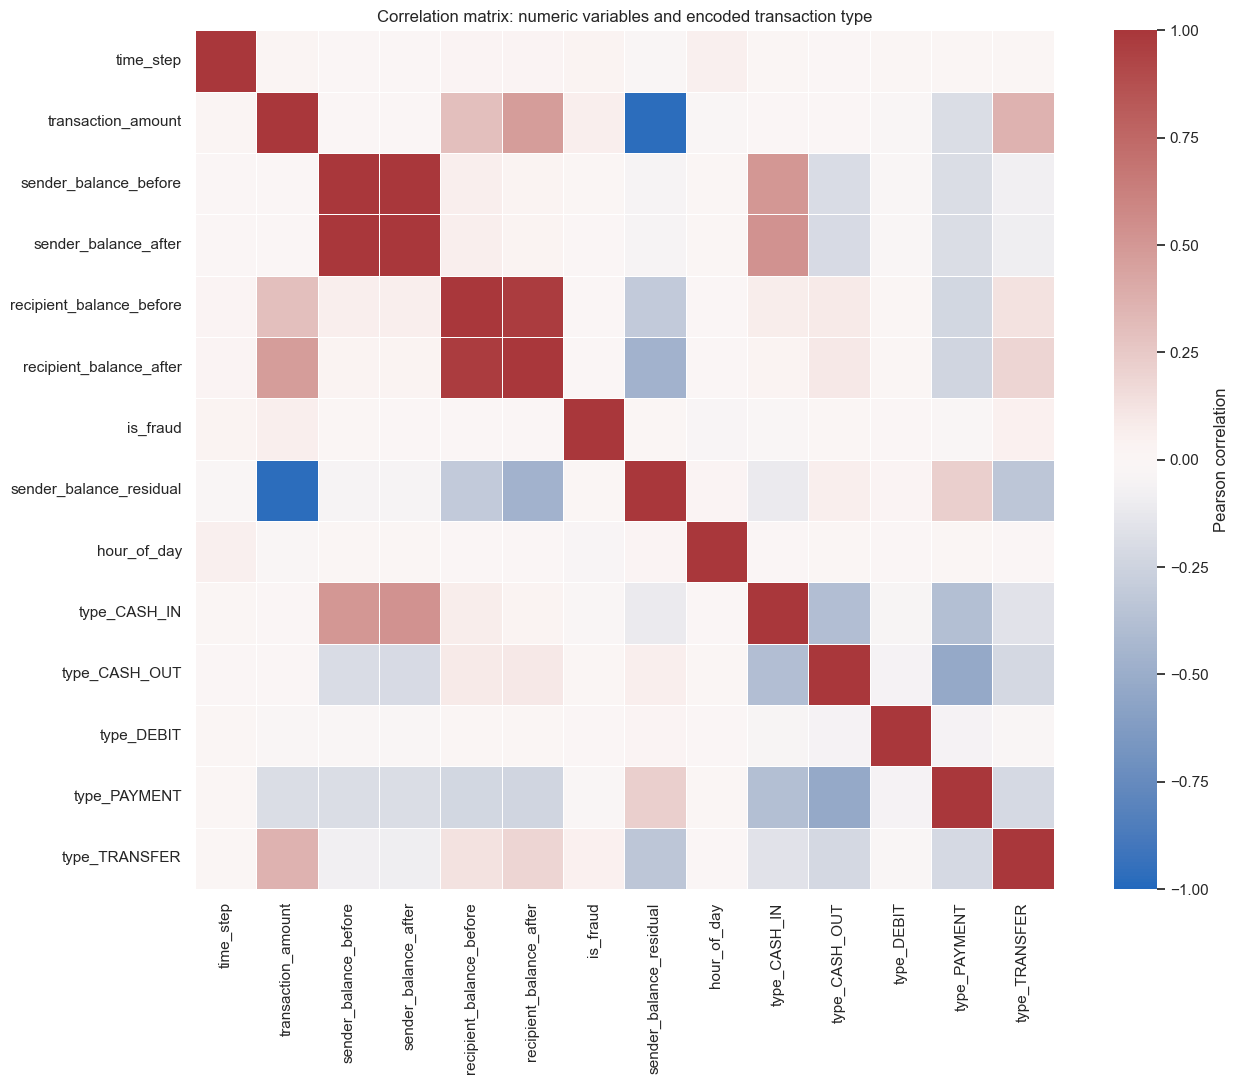

correlation
transaction_amount       sender_balance_residual     -0.974399
type_CASH_OUT            type_PAYMENT                -0.526798
recipient_balance_after  sender_balance_residual     -0.468493
type_CASH_IN             type_CASH_OUT               -0.390493
                         type_PAYMENT                -0.378993
sender_balance_residual  type_TRANSFER               -0.329607
recipient_balance_before sender_balance_residual     -0.309324
recipient_balance_after  type_PAYMENT                -0.237462
recipient_balance_before type_PAYMENT                -0.230889
type_CASH_OUT            type_TRANSFER               -0.223215
recipient_balance_before type_TRANSFER                0.129056
recipient_balance_after  type_TRANSFER                0.190877
sender_balance_residual  type_PAYMENT                 0.224372
transaction_amount       recipient_balance_before     0.300738
                         type_TRANSFER                0.363020
                         recipient_balance_after      0.470022
sender_balance_before    type_CASH_IN                 0.506572
sender_balance_after     type_CASH_IN                 0.527136
recipient_balance_before recipient_balance_after      0.976094
sender_balance_before    sender_balance_after         0.998892

In [11]:
numeric_columns = [
    'time_step', 'transaction_amount', 'sender_balance_before', 'sender_balance_after',
    'recipient_balance_before', 'recipient_balance_after', 'is_fraud',
    'sender_balance_residual', 'hour_of_day'
]
type_dummies = pd.get_dummies(df['transaction_type'], prefix='type', dtype=int)
corr_data = pd.concat([df[numeric_columns], type_dummies], axis=1)
corr_matrix = corr_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr_matrix, cmap='vlag', center=0, vmin=-1, vmax=1,
    square=True, linewidths=.4, cbar_kws={'label': 'Pearson correlation'}, ax=ax
)
ax.set_title('Correlation matrix: numeric variables and encoded transaction type')
plt.tight_layout()
plt.show()

# Most positive and negative non-self correlations, useful for quick review.
pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
               .stack().rename('correlation').sort_values()
)
display(pd.concat([pairs.head(10), pairs.tail(10)]).to_frame())


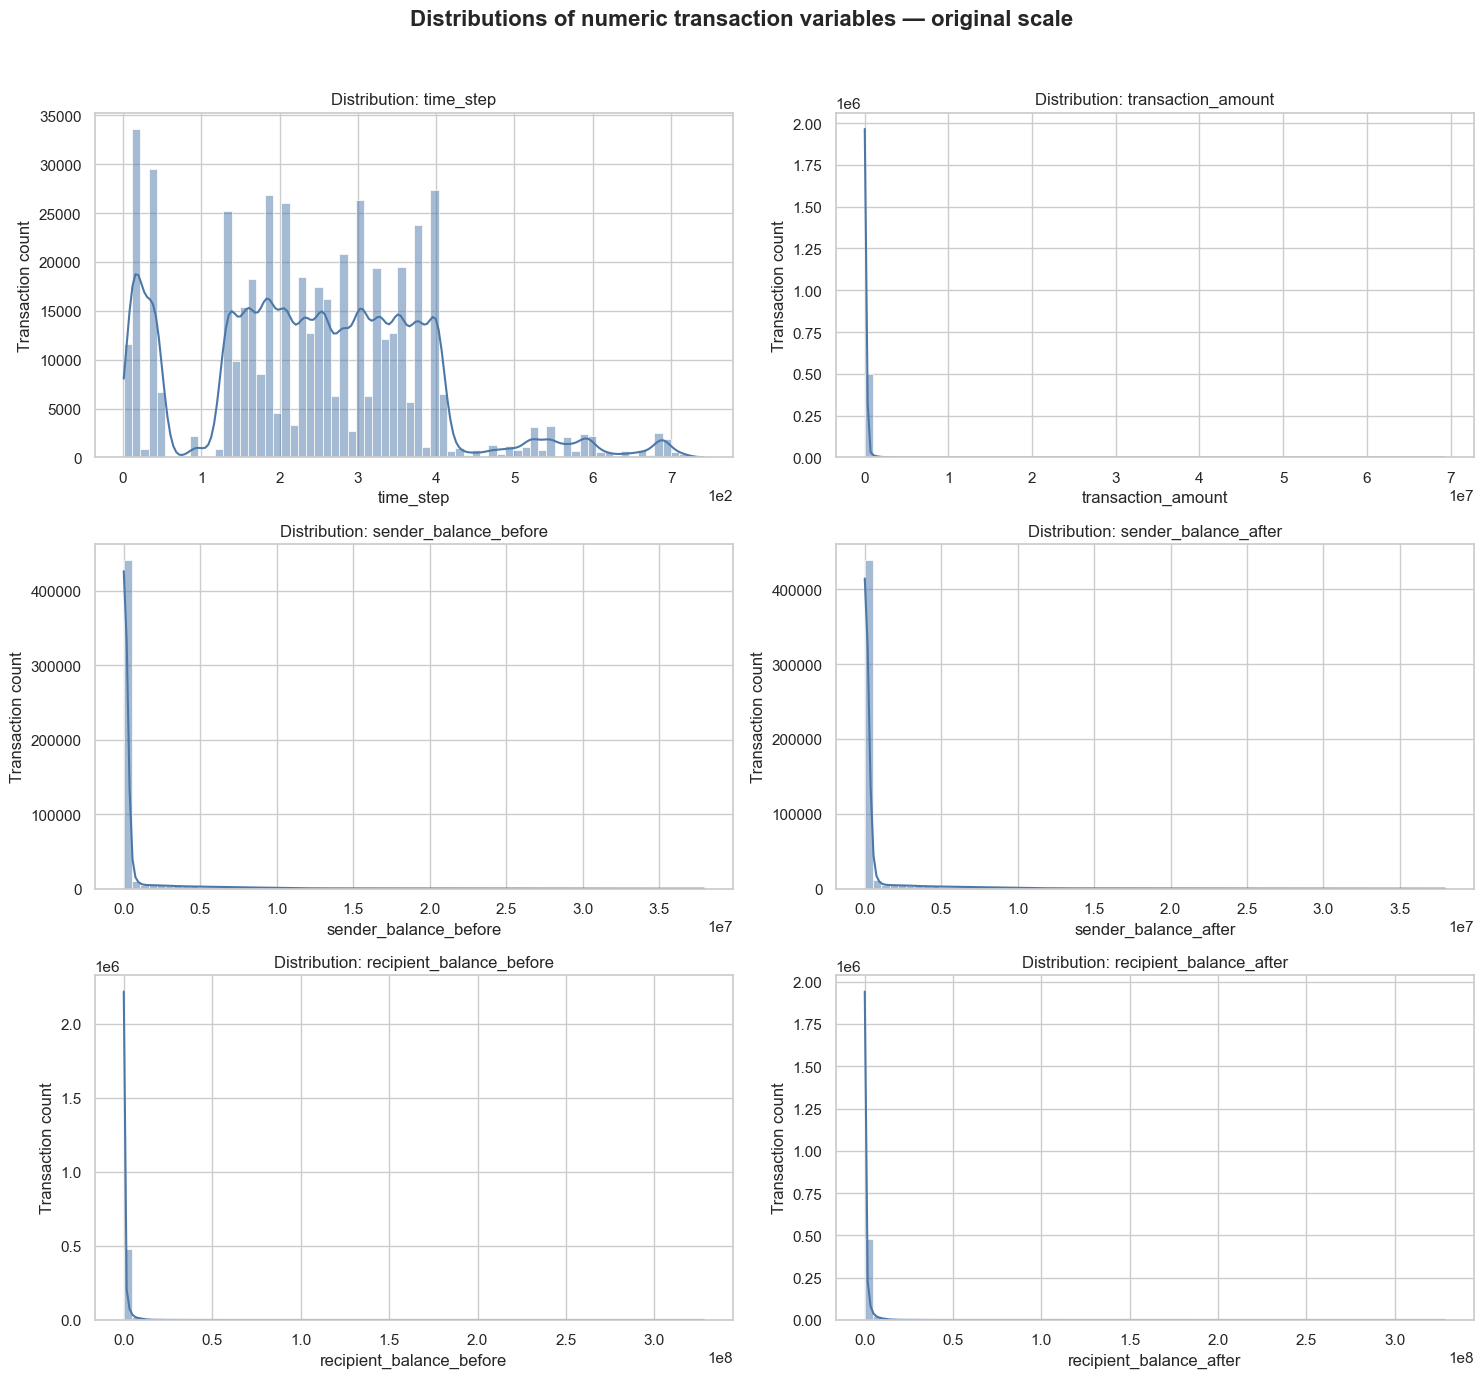

In [15]:
continuous_cols = [
    "time_step",
    "transaction_amount",
    "sender_balance_before",
    "sender_balance_after",
    "recipient_balance_before",
    "recipient_balance_after",
]

ncols = 2
nrows = int(np.ceil(len(continuous_cols) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, continuous_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=70,
        kde=True,
        color="#4C78A8",
        ax=ax
    )

    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Transaction count")

    # Keep the original scale but format large values compactly.
    ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

for ax in axes[len(continuous_cols):]:
    ax.remove()

plt.suptitle(
    "Distributions of numeric transaction variables — original scale",
    y=1.02,
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

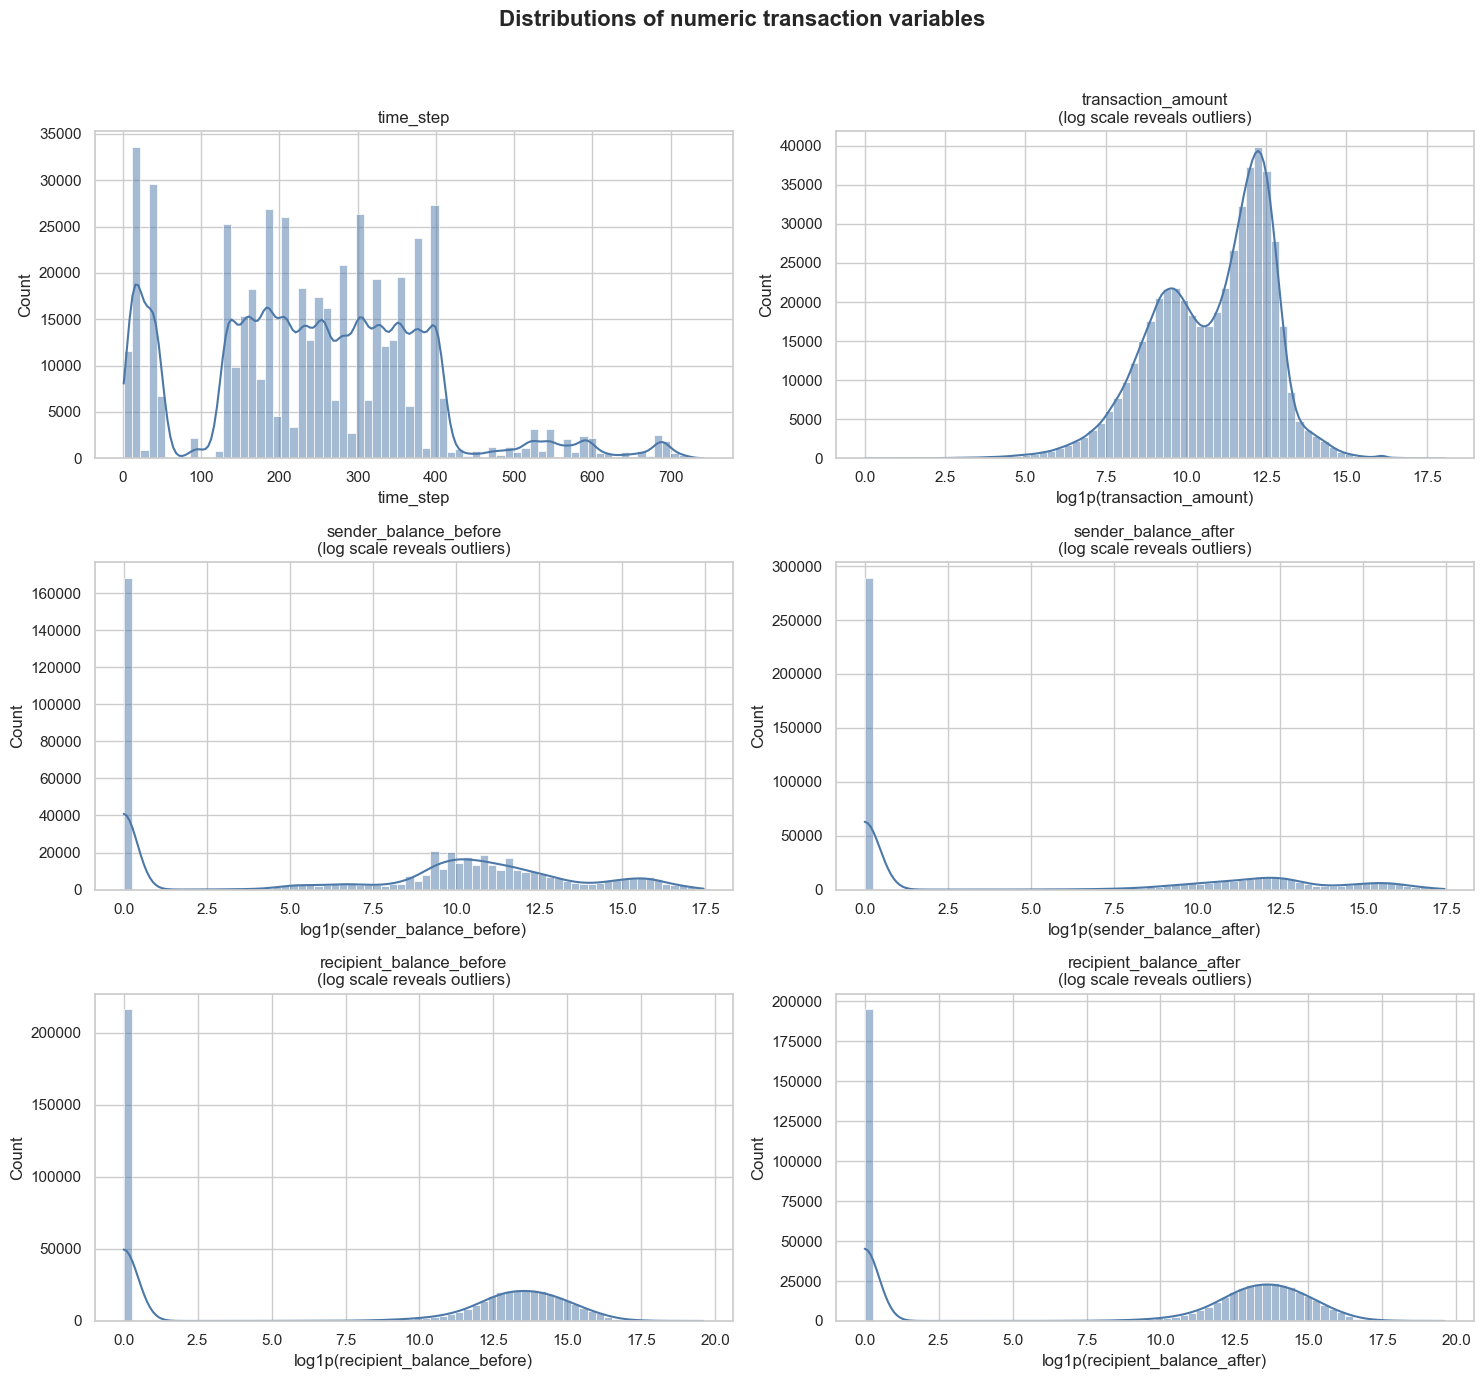

In [14]:
# Numeric distribution plots
# log1p is used for non-negative money/balance variables so extreme values remain visible.

continuous_cols = [
    "time_step",
    "transaction_amount",
    "sender_balance_before",
    "sender_balance_after",
    "recipient_balance_before",
    "recipient_balance_after",
]

ncols = 2
nrows = int(np.ceil(len(continuous_cols) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, continuous_cols):
    values = df[col].dropna()

    if values.min() >= 0 and col != "time_step":
        transformed = np.log1p(values)
        sns.histplot(transformed, bins=70, kde=True, ax=ax, color="#4C78A8")
        ax.set_xlabel(f"log1p({col})")
        ax.set_title(f"{col}\n(log scale reveals outliers)")
    else:
        sns.histplot(values, bins=70, kde=True, ax=ax, color="#4C78A8")
        ax.set_xlabel(col)
        ax.set_title(col)

for ax in axes[len(continuous_cols):]:
    ax.remove()

plt.suptitle("Distributions of numeric transaction variables", y=1.02, fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## Takeaways for the hackathon

- Use **precision and recall at the top 1% of the ranked queue** as primary performance measures.
- The `TRANSFER + emptied sender + new recipient` segment alone occupies about 1% of this sample and is substantially fraud-enriched; validate it on a time-based holdout before presenting it as a policy.
- Treat post-transaction balance fields and the perfect balance-change pattern as potential leakage. Verify feature availability at scoring time with the data dictionary.
- Build a next-step model with time-safe behavioral features and compare it with this transparent rule baseline.
